# Job Offer Acceptance Prediction: Model Training & Pipeline


In [21]:
# 1. Import Required Libraries
import os
import json
import hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')
plt.style.use('ggplot')
print('Libraries imported successfully!')

Libraries imported successfully!


In [22]:
# 2. Load the Dataset
PATH = '../dataset/job_offer_acceptance_dataset.csv'
df = pd.read_csv(PATH)
print('Initial Dataset Shape:', df.shape)
df.head()

Initial Dataset Shape: (200000, 28)


,candidate_id,age,gender,country,city,education_level,university_tier,major,years_experience,internship_count,...,remote_preference,relocation_willingness,company_size,company_rating,company_industry,application_month,application_year,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
0,CAND000001,49,Other,Singapore,Singapore,Bachelor,Tier 3,Mathematics,0.7,2,...,Onsite,Yes,Startup,2.7,Retail,9,2023,0,8737,1.1580
1,CAND000002,29,Female,India,Hyderabad,Bachelor,Tier 1,Statistics,2.3,3,...,Remote,Yes,Startup,4.5,Technology,9,2026,0,13966,1.1896
2,CAND000003,21,Other,Japan,Osaka,Bachelor,Tier 1,Artificial Intelligence,0.9,2,...,Onsite,No,Medium,3.7,Education,4,2025,0,-3782,0.9324
3,CAND000004,35,Female,Canada,Montreal,Master,Tier 1,Artificial Intelligence,4.7,3,...,Hybrid,No,Enterprise,3.9,Retail,1,2021,1,14368,1.1829
4,CAND000005,22,Male,Germany,Munich,Master,Tier 1,Computer Science,1.2,1,...,Onsite,Yes,Enterprise,4.1,Retail,9,2020,0,5840,1.1133


In [23]:
# 3. Drop Unwanted / Noisy Features
features_to_drop = [
    'candidate_id', 'major', 'university_tier', 'city', 'education_level',
    'kaggle_score', 'linkedin_connections', 'internship_count',
    'github_repositories', 'hackathons_participated', 'leadership_experience',
    'company_industry', 'publications_count', 'application_month', 'application_year'
]

df = df.drop(columns=[c for c in features_to_drop if c in df.columns])
print('Shape after dropping unwanted features:', df.shape)
df.head()

Shape after dropping unwanted features: (200000, 13)


,age,gender,country,years_experience,expected_salary_usd,offered_salary_usd,remote_preference,relocation_willingness,company_size,company_rating,offer_accepted,salary_offer_gap_usd,offer_to_expected_salary_ratio
0,49,Other,Singapore,0.7,55304,64041,Onsite,Yes,Startup,2.7,0,8737,1.1580
1,29,Female,India,2.3,73673,87639,Remote,Yes,Startup,4.5,0,13966,1.1896
2,21,Other,Japan,0.9,55910,52128,Onsite,No,Medium,3.7,0,-3782,0.9324
3,35,Female,Canada,4.7,78573,92941,Hybrid,No,Enterprise,3.9,1,14368,1.1829
4,22,Male,Germany,1.2,51525,57365,Onsite,Yes,Enterprise,4.1,0,5840,1.1133


In [24]:
# 4. Feature Engineering
# Create salary gap, ratio, percentage hike, and experience to age ratio
df['salary_offer_gap_usd'] = df['offered_salary_usd'] - df['expected_salary_usd']
df['offer_to_expected_salary_ratio'] = df['offered_salary_usd'] / df['expected_salary_usd'].replace(0, 1)
df['salary_hike_pct'] = (df['salary_offer_gap_usd'] / df['expected_salary_usd'].replace(0, 1)) * 100
df['exp_to_age_ratio'] = df['years_experience'] / df['age'].replace(0, 1)

print('Engineered Features Created Successfully!')
df[['salary_offer_gap_usd', 'offer_to_expected_salary_ratio', 'salary_hike_pct', 'exp_to_age_ratio']].head()

Engineered Features Created Successfully!


,salary_offer_gap_usd,offer_to_expected_salary_ratio,salary_hike_pct,exp_to_age_ratio
0,8737,1.157981,15.798134,0.014286
1,13966,1.189567,18.956741,0.079310
2,-3782,0.932356,-6.764443,0.042857
3,14368,1.182862,18.286180,0.134286
4,5840,1.113343,11.334304,0.054545


In [25]:
# 5. Separate Features (X) and Target (y)
TARGET = 'offer_accepted'

X = df.drop(columns=[TARGET])
y = df[TARGET]

print(f'Features shape: {X.shape}, Target shape: {y.shape}')

Features shape: (200000, 14), Target shape: (200000,)


In [26]:
# 6. Identify Numerical and Categorical Columns
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print(f'Numerical columns ({len(numerical_cols)}): {numerical_cols}')
print(f'Categorical columns ({len(categorical_cols)}): {categorical_cols}')

Numerical columns (9): ['age', 'years_experience', 'expected_salary_usd', 'offered_salary_usd', 'company_rating', 'salary_offer_gap_usd', 'offer_to_expected_salary_ratio', 'salary_hike_pct', 'exp_to_age_ratio']
Categorical columns (5): ['gender', 'country', 'remote_preference', 'relocation_willingness', 'company_size']


In [27]:
# 7. Build Numerical and Categorical Preprocessing Pipelines

# Numerical Pipeline: Impute missing values with mean + Standard Scaling
numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# Categorical Pipeline: Impute missing values with mode + OneHotEncoder
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Combine both pipelines using ColumnTransformer
preprocessor = ColumnTransformer([
    ('numerical', numerical_pipeline, numerical_cols),
    ('categorical', categorical_pipeline, categorical_cols)
])

print('Numerical and categorical preprocessing pipelines created successfully!')

Numerical and categorical preprocessing pipelines created successfully!


In [28]:
# 8. Train-Test Split (Stratified 80/20) & Class Imbalance Calculation
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Calculate scale_pos_weight for XGBoost to balance 67% Rejected / 33% Accepted
scale_pos_weight = float((len(y_train) - sum(y_train)) / sum(y_train))
print(f'Train samples: {len(X_train):,}, Test samples: {len(X_test):,}')
print(f'Computed scale_pos_weight: {scale_pos_weight:.2f}')

Train samples: 160,000, Test samples: 40,000
Computed scale_pos_weight: 2.01


In [29]:
# 9. Stratified 5-Fold Cross-Validation on Baseline Models
# Using a 30,000 sample slice for quick and reliable cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sample_idx = np.random.RandomState(42).choice(len(X_train), size=30000, replace=False)
X_cv = X_train.iloc[sample_idx]
y_cv = y_train.iloc[sample_idx]

models_to_test = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=10, class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(n_estimators=60, max_depth=5, scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
}

cv_summary = []
for name, model in models_to_test.items():
    full_pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    scores = cross_val_score(full_pipe, X_cv, y_cv, cv=skf, scoring='f1')
    cv_summary.append({
        'Model': name,
        'Mean F1 Score (%)': round(scores.mean() * 100, 2),
        'F1 Std Dev (%)': round(scores.std() * 100, 2)
    })

print('Stratified 5-Fold Cross-Validation Results:')
pd.DataFrame(cv_summary)

Stratified 5-Fold Cross-Validation Results:


,Model,Mean F1 Score (%),F1 Std Dev (%)
0,Logistic Regression,57.80,1.08
1,Decision Tree,56.65,0.52
2,Random Forest,57.35,1.26
3,XGBoost,57.33,1.05


In [30]:
# 10. Fit and Benchmark Models on Full Training Split
# Preprocess features once for fast model training
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

benchmark_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=120, max_depth=5, learning_rate=0.08, scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss')
}

benchmark_rows = []
fitted_models = {}

for name, model in benchmark_models.items():
    model.fit(X_train_proc, y_train)
    preds = model.predict(X_test_proc)
    probs = model.predict_proba(X_test_proc)[:, 1]
    
    fitted_models[name] = model
    benchmark_rows.append({
        'Model': name,
        'Accuracy (%)': round(accuracy_score(y_test, preds) * 100, 2),
        'Precision (%)': round(precision_score(y_test, preds) * 100, 2),
        'Recall (%)': round(recall_score(y_test, preds) * 100, 2),
        'F1 Score (%)': round(f1_score(y_test, preds) * 100, 2),
        'ROC-AUC (%)': round(roc_auc_score(y_test, probs) * 100, 2)
    })

benchmark_df = pd.DataFrame(benchmark_rows).sort_values('F1 Score (%)', ascending=False).reset_index(drop=True)
print('Model Benchmark Performance on Test Split:')
benchmark_df

Model Benchmark Performance on Test Split:


,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC (%)
0,XGBoost,69.96,53.89,65.33,59.06,75.91
1,Random Forest,70.96,55.59,61.84,58.55,75.81
2,Logistic Regression,70.08,54.23,62.67,58.15,75.15
3,Decision Tree,68.73,52.32,64.51,57.78,74.15


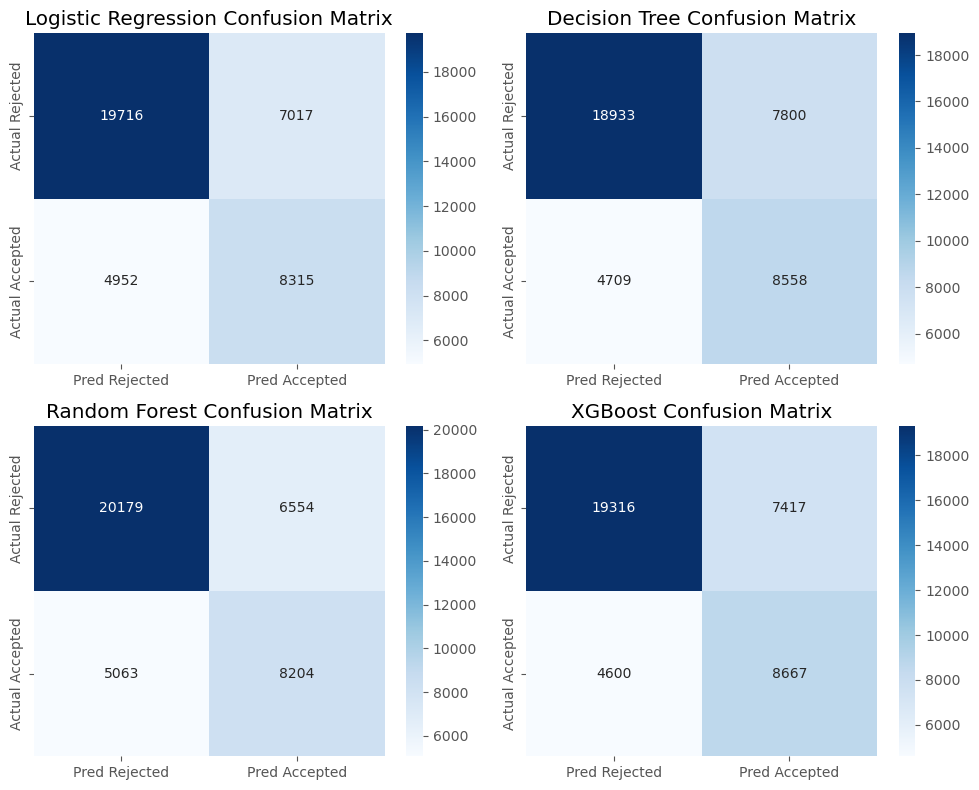

In [31]:
# 11. Plot Confusion Matrices for All 4 Models
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes = axes.flatten()

for i, (name, model) in enumerate(fitted_models.items()):
    preds = model.predict(X_test_proc)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Pred Rejected', 'Pred Accepted'],
                yticklabels=['Actual Rejected', 'Actual Accepted'])
    axes[i].set_title(f'{name} Confusion Matrix')

plt.tight_layout()
plt.show()

In [32]:
# 12. Hyperparameter Tuning: RandomizedSearchCV & GridSearchCV
# Tune on a 20,000 representative sample slice
tune_idx = np.random.RandomState(42).choice(len(X_train_proc), size=20000, replace=False)
X_tune = X_train_proc[tune_idx]
y_tune = y_train.iloc[tune_idx]

# Stage 1: RandomizedSearchCV across a parameter distribution
param_dist = {
    'n_estimators': [80, 100, 120],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.05, 0.08, 0.1]
}

random_search = RandomizedSearchCV(
    estimator=XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
    param_distributions=param_dist,
    n_iter=5,
    cv=3,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_tune, y_tune)
print('Best Parameters from RandomizedSearchCV:', random_search.best_params_)

# Stage 2: GridSearchCV fine-tuning
best_depth = random_search.best_params_['max_depth']
param_grid = {
    'max_depth': [best_depth],
    'learning_rate': [0.05, 0.08],
    'n_estimators': [100, 120]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_tune, y_tune)
print('Final Best Parameters from GridSearchCV:', grid_search.best_params_)

Best Parameters from RandomizedSearchCV: {'n_estimators': 80, 'max_depth': 3, 'learning_rate': 0.08}
Final Best Parameters from GridSearchCV: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 120}


In [33]:
# 13. Assemble the Full Production Pipeline & Fit on Raw Training Data
# The Pipeline bundles preprocessing (StandardScaler + OneHotEncoder) + XGBoost Classifier
best_classifier = XGBClassifier(
    n_estimators=grid_search.best_params_['n_estimators'],
    max_depth=grid_search.best_params_['max_depth'],
    learning_rate=grid_search.best_params_['learning_rate'],
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)

production_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', best_classifier)
])

print('Fitting Full Production Pipeline (Standard Scaling + OneHotEncoding + Model Training)...')
production_pipeline.fit(X_train, y_train)

# Evaluate on held-out test data
pipe_preds = production_pipeline.predict(X_test)
pipe_probs = production_pipeline.predict_proba(X_test)[:, 1]

print('--- Production Pipeline Test Performance ---')
print(f'Accuracy: {accuracy_score(y_test, pipe_preds) * 100:.2f}%')
print(f'F1 Score: {f1_score(y_test, pipe_preds) * 100:.2f}%')
print(f'ROC-AUC:  {roc_auc_score(y_test, pipe_probs) * 100:.2f}%')

Fitting Full Production Pipeline (Standard Scaling + OneHotEncoding + Model Training)...
--- Production Pipeline Test Performance ---
Accuracy: 69.82%
F1 Score: 59.05%
ROC-AUC:  75.93%


In [34]:
# 14. Save Pipeline and Model Artifacts to models/
models_dir = '../models' if os.path.exists('../models') else 'models'
os.makedirs(models_dir, exist_ok=True)

# Ensure cross-version sklearn compatibility for SimpleImputer
for _, transformer in production_pipeline.named_steps['preprocessor'].transformers:
    if hasattr(transformer, 'named_steps') and 'imputer' in transformer.named_steps:
        imp = transformer.named_steps['imputer']
        if not hasattr(imp, '_fill_dtype'):
            imp._fill_dtype = getattr(imp, '_fit_dtype', np.float64)

# Save the primary pipeline
pipeline_path = os.path.join(models_dir, 'pipeline.pkl')
joblib.dump(production_pipeline, pipeline_path)
print(f'Production Pipeline saved successfully to: {pipeline_path}')

# Save individual models
joblib.dump(best_classifier, os.path.join(models_dir, 'best_model.pkl'))
joblib.dump(fitted_models['XGBoost'], os.path.join(models_dir, 'xgboost.pkl'))
joblib.dump(fitted_models['Random Forest'], os.path.join(models_dir, 'random_forest.pkl'))
joblib.dump(fitted_models['Decision Tree'], os.path.join(models_dir, 'decision_tree.pkl'))
joblib.dump(fitted_models['Logistic Regression'], os.path.join(models_dir, 'logistic.pkl'))

# Save encoders and scaler for standalone model scoring
encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    le.fit(X[col].astype(str))
    encoders[col] = le

scaler = StandardScaler()
X_enc = X.copy()
for col in categorical_cols:
    X_enc[col] = encoders[col].transform(X_enc[col].astype(str))
scaler.fit(X_enc)

joblib.dump(encoders, os.path.join(models_dir, 'encoders.pkl'))
joblib.dump(scaler, os.path.join(models_dir, 'scaler.pkl'))
joblib.dump(X_enc.columns.tolist(), os.path.join(models_dir, 'feature_names.pkl'))

# Save model metrics for the Streamlit dashboard
metrics_records = []
for row in benchmark_rows:
    metrics_records.append({
        'Model': row['Model'],
        'Accuracy': row['Accuracy (%)'],
        'Precision': row['Precision (%)'],
        'Recall': row['Recall (%)'],
        'F1 Score': row['F1 Score (%)'],
        'ROC-AUC': row['ROC-AUC (%)']
    })

metrics_payload = {
    'dataset_sha256': hashlib.sha256(open(PATH, 'rb').read()).hexdigest(),
    'models': metrics_records
}

with open(os.path.join(models_dir, 'model_metrics.json'), 'w', encoding='utf-8') as f:
    json.dump(metrics_payload, f, indent=2)

print('All model artifacts and model_metrics.json saved successfully!')

Production Pipeline saved successfully to: ../models\pipeline.pkl
All model artifacts and model_metrics.json saved successfully!


In [35]:
# 15. Verify Live Pipeline Inference on Sample Candidates
loaded_pipe = joblib.load(pipeline_path)

test_candidates = [
    {
        'profile': 'Candidate A (High Acceptance Profile)',
        'data': {
            'age': 30,
            'gender': 'Male',
            'country': 'USA',
            'years_experience': 6.0,
            'expected_salary_usd': 85000,
            'offered_salary_usd': 100000,
            'remote_preference': 'Hybrid',
            'relocation_willingness': 'Yes',
            'company_size': 'Enterprise',
            'company_rating': 4.6,
            'salary_offer_gap_usd': 15000,
            'offer_to_expected_salary_ratio': 1.176,
            'salary_hike_pct': 17.65,
            'exp_to_age_ratio': 0.20
        }
    },
    {
        'profile': 'Candidate B (Offer-at-Risk Profile)',
        'data': {
            'age': 25,
            'gender': 'Female',
            'country': 'India',
            'years_experience': 2.0,
            'expected_salary_usd': 85000,
            'offered_salary_usd': 65000,
            'remote_preference': 'Onsite',
            'relocation_willingness': 'No',
            'company_size': 'Startup',
            'company_rating': 2.3,
            'salary_offer_gap_usd': -20000,
            'offer_to_expected_salary_ratio': 0.765,
            'salary_hike_pct': -23.53,
            'exp_to_age_ratio': 0.08
        }
    }
]

print('Testing Live Pipeline Prediction on Raw Inputs:')
for item in test_candidates:
    cand_df = pd.DataFrame([item['data']])
    # The pipeline automatically scales numericals and encodes categoricals:
    pred = loaded_pipe.predict(cand_df)[0]
    prob = loaded_pipe.predict_proba(cand_df)[0]
    
    verdict = 'ACCEPT (1)' if pred == 1 else 'REJECT (0)'
    print(f"{item['profile']} -> {verdict} | Acceptance Prob: {prob[1]*100:.2f}% | Rejection Prob: {prob[0]*100:.2f}%")

Testing Live Pipeline Prediction on Raw Inputs:
Candidate A (High Acceptance Profile) -> ACCEPT (1) | Acceptance Prob: 74.30% | Rejection Prob: 25.70%
Candidate B (Offer-at-Risk Profile) -> REJECT (0) | Acceptance Prob: 15.08% | Rejection Prob: 84.92%
